## BƯỚC 1. CHUẨN BỊ THƯ VIỆN VÀ TẢI DỮ LIỆU

In [1]:
# Import các thư viện cần thiết
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

from sklearn import datasets, tree, metrics
from sklearn.model_selection import train_test_split

print("Họ và tên: Nguyễn Công Vũ")
print("MSSV: 6451071089")
print("=" * 60)

# Tải bộ dữ liệu chữ số viết tay
digits = datasets.load_digits()

print("Kích thước dữ liệu:", digits.images.shape)
print("Kích thước nhãn:", digits.target.shape)
print("Số lượng mẫu:", len(digits.images))
print("Các chữ số:", np.unique(digits.target))

Họ và tên: Nguyễn Công Vũ
MSSV: 6451071089
Kích thước dữ liệu: (1797, 8, 8)
Kích thước nhãn: (1797,)
Số lượng mẫu: 1797
Các chữ số: [0 1 2 3 4 5 6 7 8 9]


## BƯỚC 2. BIỂU DIỄN 4 MẪU CHỮ SỐ ĐẦU TIÊN

Hiển thị 4 mẫu ảnh chữ số viết tay đầu tiên trong bộ dữ liệu MNIST, tương ứng với các nhãn từ 0 đến 3.

Họ và tên: Nguyễn Công Vũ
MSSV: 6451071089


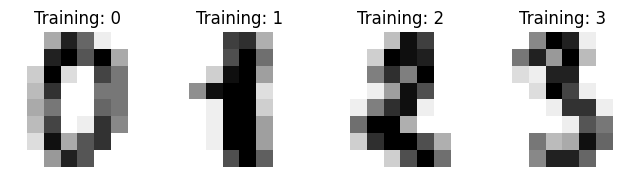

In [2]:
print("Họ và tên: Nguyễn Công Vũ")
print("MSSV: 6451071089")
print("=" * 60)

fig, axes = plt.subplots(1, 4, figsize=(8, 3))

for ax, (image, label) in zip(
    axes, zip(digits.images[:4], digits.target[:4])
):
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest')
    ax.set_title(f'Training: {label}')
    ax.axis('off')

plt.show()

## BƯỚC 3. CHUYỂN ĐỔI MA TRẬN ẢNH 8×8 THÀNH VECTOR 1×64

Chuyển mỗi ảnh từ ma trận 8×8 thành một vector 1 chiều gồm 64 phần tử để phù hợp với đầu vào của thuật toán học máy.

In [3]:
print("Họ và tên: Nguyễn Công Vũ")
print("MSSV: 6451071089")
print("=" * 60)

# Chuyển ma trận ảnh 8x8 thành vector 1 chiều
n_samples = len(digits.images)
data = digits.images.reshape((n_samples, -1))

print("Kích thước dữ liệu ảnh ban đầu:", digits.images.shape)
print("Kích thước dữ liệu sau khi chuyển đổi:", data.shape)
print("Vector của ảnh đầu tiên:")
print(data[0])

Họ và tên: Nguyễn Công Vũ
MSSV: 6451071089
Kích thước dữ liệu ảnh ban đầu: (1797, 8, 8)
Kích thước dữ liệu sau khi chuyển đổi: (1797, 64)
Vector của ảnh đầu tiên:
[ 0.  0.  5. 13.  9.  1.  0.  0.  0.  0. 13. 15. 10. 15.  5.  0.  0.  3.
 15.  2.  0. 11.  8.  0.  0.  4. 12.  0.  0.  8.  8.  0.  0.  5.  8.  0.
  0.  9.  8.  0.  0.  4. 11.  0.  1. 12.  7.  0.  0.  2. 14.  5. 10. 12.
  0.  0.  0.  0.  6. 13. 10.  0.  0.  0.]


## BƯỚC 4. XÂY DỰNG MÔ HÌNH CÂY QUYẾT ĐỊNH ID3

Khởi tạo mô hình Decision Tree sử dụng tiêu chí Entropy để xây dựng cây quyết định và nhận dạng chữ số viết tay.

In [4]:
print("Họ và tên: Nguyễn Công Vũ")
print("MSSV: 6451071089")
print("=" * 60)

# Khởi tạo mô hình cây quyết định ID3
classifier = tree.DecisionTreeClassifier(
    criterion='entropy',
    random_state=33
)

print("Đã khởi tạo mô hình ID3 thành công.")
print("Tiêu chí phân chia:", classifier.criterion)

Họ và tên: Nguyễn Công Vũ
MSSV: 6451071089
Đã khởi tạo mô hình ID3 thành công.
Tiêu chí phân chia: entropy


## BƯỚC 5. CHIA DỮ LIỆU THÀNH TẬP HUẤN LUYỆN VÀ KIỂM THỬ

Chia bộ dữ liệu MNIST thành hai phần:
- **80% dữ liệu** dùng để huấn luyện mô hình.
- **20% dữ liệu** dùng để kiểm thử mô hình.

Sử dụng `train_test_split()` để thực hiện việc chia dữ liệu.

In [5]:
print("Họ và tên: Nguyễn Công Vũ")
print("MSSV: 6451071089")
print("=" * 60)

# Chia dữ liệu thành tập huấn luyện và tập kiểm thử
X_train, X_test, y_train, y_test = train_test_split(
    data,
    digits.target,
    test_size=0.2,
    shuffle=False
)

print("Số lượng mẫu huấn luyện:", len(X_train))
print("Số lượng mẫu kiểm thử:", len(X_test))
print("Kích thước X_train:", X_train.shape)
print("Kích thước X_test:", X_test.shape)

Họ và tên: Nguyễn Công Vũ
MSSV: 6451071089
Số lượng mẫu huấn luyện: 1437
Số lượng mẫu kiểm thử: 360
Kích thước X_train: (1437, 64)
Kích thước X_test: (360, 64)


## Bước 6. Huấn luyện mô hình cây quyết định ID3

Sử dụng 80% dữ liệu huấn luyện để xây dựng cây quyết định ID3 với tiêu chí Entropy.

In [6]:
print("Họ và tên: Nguyễn Công Vũ")
print("MSSV: 6451071089")
print("=" * 60)

# Huấn luyện mô hình ID3
classifier.fit(X_train, y_train)

print("Đã huấn luyện mô hình ID3 thành công.")

Họ và tên: Nguyễn Công Vũ
MSSV: 6451071089
Đã huấn luyện mô hình ID3 thành công.


## Bước 7. Dự đoán nhãn chữ số trên tập kiểm thử

Sử dụng mô hình ID3 đã huấn luyện để dự đoán các chữ số trong tập kiểm thử và hiển thị một số kết quả dự đoán.

Họ và tên: Nguyễn Công Vũ
MSSV: 6451071089


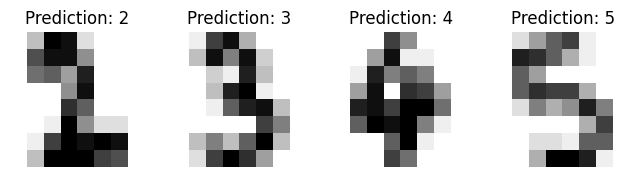

In [7]:
print("Họ và tên: Nguyễn Công Vũ")
print("MSSV: 6451071089")
print("=" * 60)

# Dự đoán trên tập kiểm thử
predicted = classifier.predict(X_test)

# Hiển thị 4 kết quả dự đoán đầu tiên
fig, axes = plt.subplots(1, 4, figsize=(8, 3))

for ax, image, prediction in zip(
    axes, X_test[:4], predicted[:4]
):
    ax.imshow(image.reshape(8, 8), cmap=plt.cm.gray_r,
              interpolation='nearest')
    ax.set_title(f'Prediction: {prediction}')
    ax.axis('off')

plt.show()

## Bước 8. Đánh giá mô hình và hiển thị ma trận nhầm lẫn

Sử dụng Classification Report để đánh giá độ chính xác, Precision, Recall và F1-score. Đồng thời, hiển thị Confusion Matrix để quan sát kết quả dự đoán đúng và sai của mô hình.

Họ và tên: Nguyễn Công Vũ
MSSV: 6451071089
Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.89      0.87        35
           1       0.72      0.64      0.68        36
           2       0.76      0.74      0.75        35
           3       0.69      0.59      0.64        37
           4       0.86      0.84      0.85        37
           5       0.80      0.95      0.86        37
           6       0.97      0.95      0.96        37
           7       0.78      0.86      0.82        36
           8       0.79      0.82      0.81        33
           9       0.72      0.70      0.71        37

    accuracy                           0.80       360
   macro avg       0.80      0.80      0.79       360
weighted avg       0.80      0.80      0.79       360



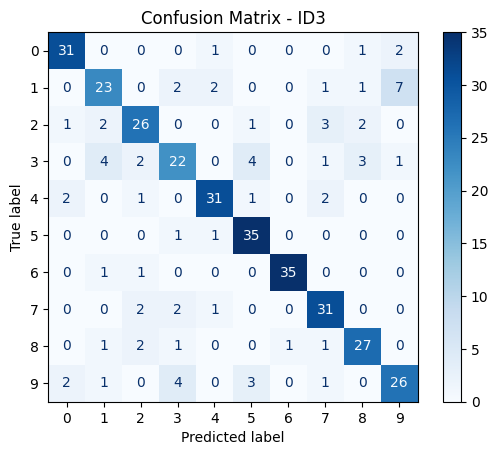

In [8]:
print("Họ và tên: Nguyễn Công Vũ")
print("MSSV: 6451071089")
print("=" * 60)

# Báo cáo đánh giá mô hình
print("Classification Report:")
print(metrics.classification_report(y_test, predicted))

# Ma trận nhầm lẫn
disp = metrics.ConfusionMatrixDisplay.from_predictions(
    y_test, predicted,
    cmap=plt.cm.Blues
)

plt.title("Confusion Matrix - ID3")
plt.show()

## BƯỚC 8. NHẬN DẠNG CHỮ SỐ VIẾT TAY TỪ ẢNH BÊN NGOÀI

Đọc ảnh chữ số viết tay bên ngoài bằng thư viện PIL. Tiến hành chuyển ảnh sang ảnh xám, thay đổi kích thước 8×8, đảo màu, làm rõ giá trị đen – trắng và chuyển thành vector 1×64. Cuối cùng, sử dụng mô hình ID3 đã huấn luyện để nhận dạng chữ số.

##8.1. Đọc ảnh và chuyển về ảnh xám kích thước 8×8

Họ và tên: Nguyễn Công Vũ
MSSV: 6451071089


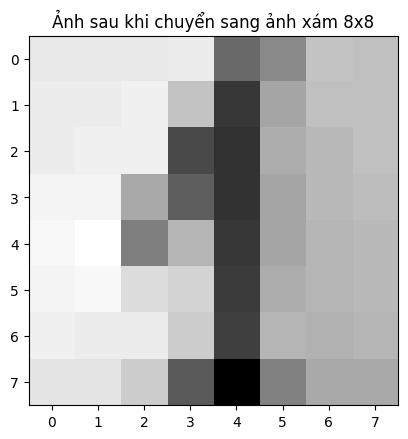

In [10]:
print("Họ và tên: Nguyễn Công Vũ")
print("MSSV: 6451071089")
print("=" * 60)

from PIL import Image, ImageOps
import numpy as np
import matplotlib.pyplot as plt

# Đọc ảnh
img = Image.open('/content/test_image_Bai7.jpg').convert('L')

# Chuyển ảnh về kích thước 8x8
img = img.resize((8, 8))

# Đảo màu ảnh
img = ImageOps.invert(img)

# Chuyển thành mảng NumPy
img2arr = np.array(img)

# Hiển thị ảnh sau khi chuyển đổi
plt.imshow(img2arr, cmap=plt.cm.gray_r, interpolation='nearest')
plt.title("Ảnh sau khi chuyển sang ảnh xám 8x8")
plt.show()

##8.2. Làm rõ ảnh bằng cách phân biệt giá trị đen và trắng

In [11]:
print("Họ và tên: Nguyễn Công Vũ")
print("MSSV: 6451071089")
print("=" * 60)

# Chuyển mảng 2 chiều (8x8) thành mảng 1 chiều (1x64)
img1d = img2arr.reshape(1, 64)

# Phân ngưỡng ảnh
img1d[img1d > 110] = 155
img1d[img1d < 110] = 0

print(img1d)

Họ và tên: Nguyễn Công Vũ
MSSV: 6451071089
[[  0   0   0   0 155   0   0   0   0   0   0   0 155   0   0   0   0   0
    0 155 155   0   0   0   0   0   0 155 155   0   0   0   0   0   0   0
  155   0   0   0   0   0   0   0 155   0   0   0   0   0   0   0 155   0
    0   0   0   0   0 155 155   0   0   0]]


##8.3. Hiển thị hình ảnh chữ số sau khi làm rõ


Họ và tên: Nguyễn Công Vũ
MSSV: 6451071089


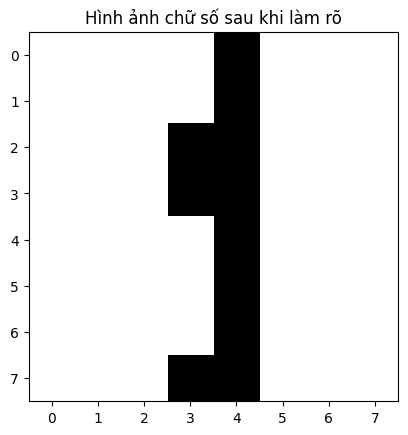

In [12]:
print("Họ và tên: Nguyễn Công Vũ")
print("MSSV: 6451071089")
print("=" * 60)

# Hiển thị ảnh sau khi phân ngưỡng
plt.imshow(img2arr, cmap=plt.cm.gray_r, interpolation='nearest')
plt.title("Hình ảnh chữ số sau khi làm rõ")
plt.show()

##8.4. Tiến hành nhận diện bằng cây ID3 và in ra kết quả

In [13]:
print("Họ và tên: Nguyễn Công Vũ")
print("MSSV: 6451071089")
print("=" * 60)

# Dự đoán chữ số
y_pred = classifier.predict(img1d)

print("Chữ số được nhận dạng:", y_pred)

Họ và tên: Nguyễn Công Vũ
MSSV: 6451071089
Chữ số được nhận dạng: [1]
